In [1]:
import sys

sys.path.append("../src")

In [3]:
import time

import matplotlib.pyplot as plt
import numpy as np

from geometry import sample_convex_shapes, signed_distance
from solvers.lbm import solve_batch

In [4]:
Ny, Nx, cx, cy = 100, 400, 100, 50
rng = np.random.default_rng(0)
masks, radii = sample_convex_shapes(
    3, Ny, Nx, cx, cy, r0=10, eps=0.15, ell=1.0, rng=rng, min_ratio=1.0
)

TypeError: sample_convex_shapes() got an unexpected keyword argument 'min_ratio'

In [ ]:
results = []
for k, mask in enumerate(masks):
    t0 = time.perf_counter()
    rho, u, _, steps = solve_batch(Re=20, n_steps=40_000, mask=mask)
    elapsed = time.perf_counter() - t0
    results.append((rho, u))
    print(f"shape {k}: {steps} steps, {elapsed:.1f} s, converged={steps < 40_000}")


shape 0: 12500 steps, 34.0 s, converged=True
shape 1: 11500 steps, 31.0 s, converged=True
shape 2: 11500 steps, 32.2 s, converged=True


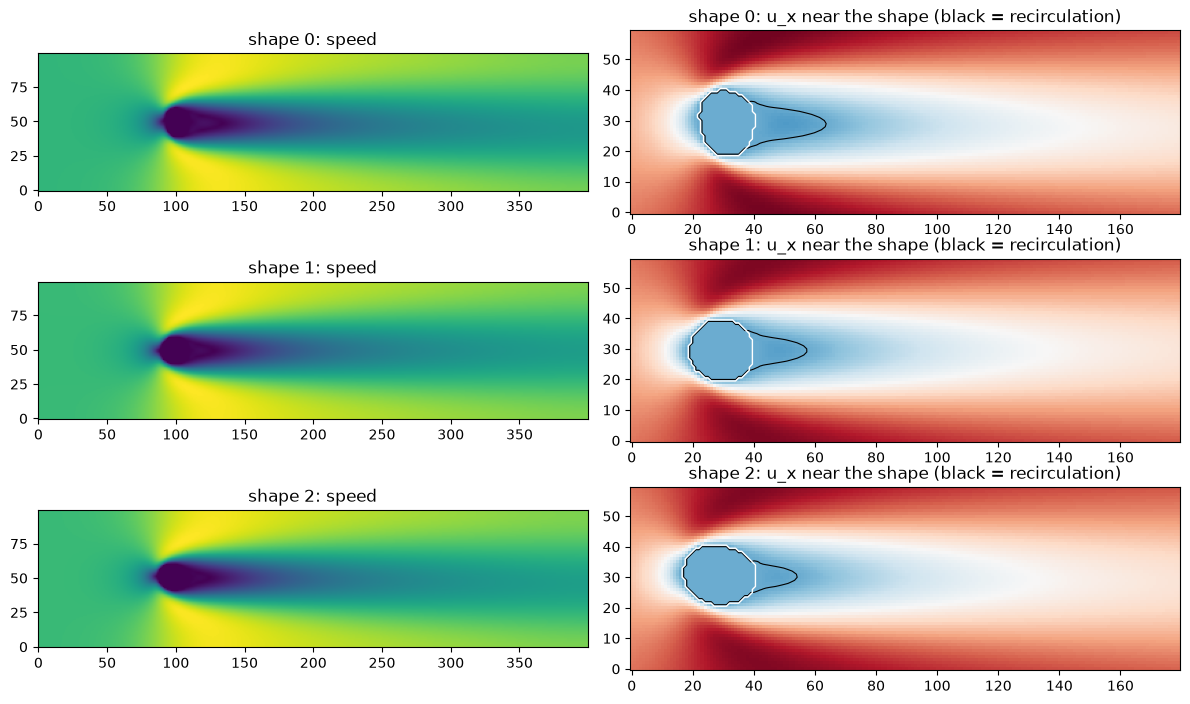

In [ ]:
fig, axes = plt.subplots(3, 2, figsize=(12, 7))
for k, (rho, u) in enumerate(results):
    speed = np.hypot(u[0], u[1])
    axes[k, 0].imshow(speed, origin="lower", cmap="viridis")
    axes[k, 0].set_title(f"shape {k}: speed")
    axes[k, 1].imshow(
        u[0][20:80, 70:250], origin="lower", cmap="RdBu_r", vmin=-0.05, vmax=0.15
    )
    axes[k, 1].contour(u[0][20:80, 70:250], levels=[0], colors="k", linewidths=0.8)
    axes[k, 1].contour(masks[k][20:80, 70:250], levels=[0.5], colors="w", linewidths=1)
    axes[k, 1].set_title(f"shape {k}: u_x near the shape (black = recirculation)")
plt.tight_layout()
plt.show()